[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/03_logistic-regression.ipynb)

*Machine Learning from Scratch · Notebook 3 of 10*

# Logistic Regression & Classification

Predicting categories: the sigmoid, odds and log-odds, log-loss, training by Newton's method, decision boundaries, thresholds, regularisation, softmax for many classes, and the perceptron.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Logistic regression squeezes a straight-line score through a sigmoid, so it becomes a probability.

**What interviewers really test here:** Why not squared error, log-loss, thresholds and the decision boundary.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. From a line to a probability *(Basics)*
- [ ] 2. The sigmoid and odds, by hand *(Basics)*
- [ ] 3. Training: log-loss *(Core)*
- [ ] 4. Decision boundaries in two dimensions *(Core)*
- [ ] 5. Where log-loss comes from *(Core)*
- [ ] 6. One training step, by hand *(Core)*
- [ ] 7. More than two classes, and the perceptron *(Advanced)*
- [ ] 8. Choosing the decision threshold *(Advanced)*
- [ ] 9. Softmax by hand, and when weights explode *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### The model

P(y = 1 | x) = σ(wᵀx + b), with σ(z) = 1/(1 + e⁻ᶻ). Equivalently the **log-odds** are linear: ln(p/(1 − p)) = wᵀx + b. It is a **generalised linear model** with a Bernoulli outcome and logit link. Despite the name, it is a classification model.

### Training

- Maximum likelihood ⇔ minimise log-loss L = −(1/n)Σ[y ln p + (1 − y) ln(1 − p)].
- Gradient: ∇L = Xᵀ(p − y)/n. Hessian: XᵀSX/n with S = diag(p(1 − p)) — positive semi-definite, so L is convex.
- Solvers: gradient descent/SGD, Newton's method (IRLS), L-BFGS (sklearn's default `lbfgs`), `liblinear`, `saga` (L1, large data).
- If classes are perfectly separable, unregularised weights grow without bound — regularisation keeps them finite.
- sklearn objective: ½‖w‖² + C·Σ log-loss (L2). Smaller C ⇒ stronger regularisation.

### Multiclass

| Strategy | How |
| --- | --- |
| Multinomial (softmax) | K weight vectors; pₖ = e^{zₖ}/Σe^{zⱼ}; loss = categorical cross-entropy |
| One-vs-rest (OvR) | K binary classifiers, pick the highest score |
| One-vs-one (OvO) | K(K − 1)/2 pairwise classifiers, majority vote (used by SVC) |

### Linear classifiers compared

| Model | Loss | Output |
| --- | --- | --- |
| Logistic regression | log-loss | calibrated-ish probabilities |
| Perceptron | max(0, −y·z) | class only; converges only if separable |
| Linear SVM | hinge max(0, 1 − y·z) + ‖w‖² | class + margin |
| Linear discriminant analysis | generative Gaussian model | probabilities |

### When to use logistic regression

| Good for | Weak at |
| --- | --- |
| a strong, explainable baseline; probabilities; text with many sparse features; small data; regulated settings that need reasons | curved boundaries unless you add features; feature interactions; unscaled features with a penalty |



Checklist: scale features, one-hot encode categories, tune C on a log scale, use class\_weight for imbalance, and pick the threshold on validation data.

---
# Part 2: Lessons, step by step

## Lesson 1: From a line to a probability

*Level: Basics*

For yes/no questions (spam? fraud? will the customer leave?) we want a **probability** between 0 and 1, not any number. Logistic regression computes the same weighted sum as linear regression, z = w·x + b, then squashes it with the **sigmoid**:



**p = σ(z) = 1 / (1 + e⁻ᶻ)**



Large positive z → p near 1; large negative → near 0; z = 0 → 0.5. We predict class 1 when p ≥ 0.5, i.e. when z ≥ 0 — so the **decision boundary** w·x + b = 0 is a straight line (a plane in higher dimensions).



z is the **log-odds**: ln(p/(1 − p)). So each weight says how much the log-odds rise per unit of its feature; e^w is the **odds ratio**.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

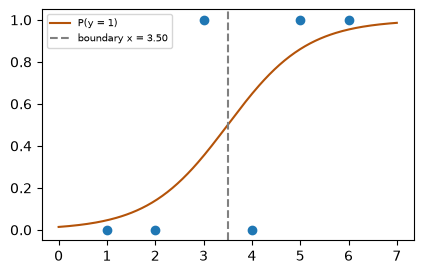

In [2]:
from sklearn.linear_model import LogisticRegression


def sigmoid_fit():
    x = np.array([1, 2, 3, 4, 5, 6])
    y = np.array([0, 0, 1, 0, 1, 1])
    model = LogisticRegression(C=1e10).fit(x.reshape(-1, 1), y)
    grid = np.linspace(0, 7, 200)
    prob = model.predict_proba(grid.reshape(-1, 1))[:, 1]
    boundary = -model.intercept_[0] / model.coef_[0, 0]
    fig, ax = plt.subplots(figsize=(4.8, 3))
    ax.scatter(x, y, zorder=3)
    ax.plot(grid, prob, color="#b45309", label="P(y = 1)")
    ax.axvline(boundary, ls="--", color="gray", label=f"boundary x = {boundary:.2f}")
    ax.legend(fontsize=7)


sigmoid_fit()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q11](#q11), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 2: The sigmoid and odds, by hand

*Level: Basics*

#### From score to probability



| Score z | −2 | −1 | 0 | 1 | 2 |
| --- | --- | --- | --- | --- | --- |
| σ(z) = 1 / (1 + e⁻ᶻ) | 0.119 | 0.269 | 0.5 | 0.731 | 0.881 |



The score can be any number, while the output always lies between 0 and 1.



#### What are odds?



Odds = p / (1 − p). A probability of 0.8 means odds of 4, or "4 to 1". The log-odds are ln 4 = 1.386, and that is the z the model computes. So logistic regression is **a straight line on the log-odds scale**.



#### Worked example: reading a coefficient



Suppose study hours have weight w = 0.7. Then e^0.7 = 2.01, so **each extra hour roughly doubles the odds of passing**.




1. A student has p = 0.2, so the odds are 0.2 / 0.8 = 0.25.
2. One more hour: 0.25 × 2.01 = 0.503.
3. Back to probability: 0.503 / 1.503 = **0.335**.



Notice that the probability doesn't double. The same weight moves p by different amounts depending on where you start, while it always multiplies the odds by the same factor.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
import math


def odds_walkthrough():
    w = 0.7
    odds_ratio = math.exp(w)
    p_before = 0.2
    odds_before = p_before / (1 - p_before)
    odds_after = odds_before * odds_ratio
    p_after = odds_after / (1 + odds_after)
    log_odds_before = math.log(odds_before)
    log_odds_after = log_odds_before + w
    check = 1 / (1 + math.exp(-log_odds_after))


odds_walkthrough()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 3: Training: log-loss

*Level: Core*

We can't use squared error well here; instead we use **log-loss** (binary cross-entropy): for each example, −ln p if the true label is 1, −ln(1 − p) if it is 0. Confident wrong answers cost a lot; confident right answers cost almost nothing.



The log-loss is convex, so gradient descent (or Newton's method) always finds the best weights. Its gradient is beautifully simple: **Xᵀ(p − y)/n** — the error times the features, just like linear regression.



sklearn's `LogisticRegression` adds L2 regularisation by default with strength 1/C: small C = strong penalty = simpler model.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

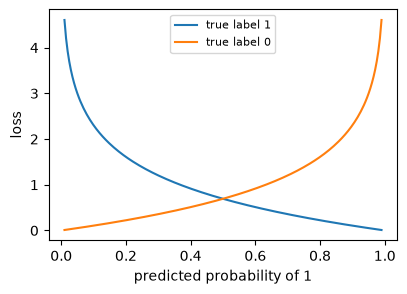

In [4]:
def log_loss_shape():
    p = np.linspace(0.01, 0.99, 200)
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.plot(p, -np.log(p), label="true label 1")
    ax.plot(p, -np.log(1 - p), label="true label 0")
    ax.set_xlabel("predicted probability of 1")
    ax.set_ylabel("loss")
    ax.legend(fontsize=8)


log_loss_shape()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q15](#q15), [Q16](#q16), [Q17](#q17), [Q18](#q18), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 4: Decision boundaries in two dimensions

*Level: Core*

With two features, the boundary w₁x₁ + w₂x₂ + b = 0 is a line through the plane: everything on one side is predicted class 1. Logistic regression can only draw **straight** boundaries — add polynomial features or use a non-linear model (trees, k-NN, kernel SVM, neural network) when the classes curve around each other.



The **threshold** 0.5 is a choice: lower it to catch more positives (higher recall, more false alarms), raise it to be more certain (higher precision). For imbalanced data, also try `class_weight="balanced"`.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

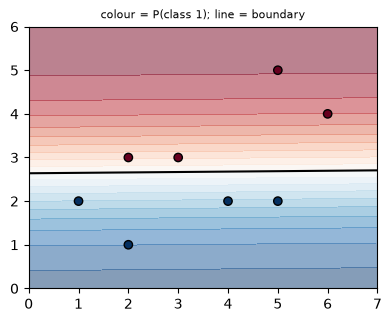

In [5]:
from sklearn.linear_model import LogisticRegression


def boundary_2d():
    X = np.array([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2]], dtype=float)
    y = np.array([0, 0, 1, 0, 1, 1, 1, 0])
    model = LogisticRegression().fit(X, y)
    xx, yy = np.meshgrid(np.linspace(0, 7, 120), np.linspace(0, 6, 120))
    prob = model.predict_proba(np.column_stack([xx.ravel(), yy.ravel()]))[:, 1].reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(4.5, 3.4))
    ax.contourf(xx, yy, prob, levels=20, cmap="RdBu_r", alpha=0.5)
    ax.contour(xx, yy, prob, levels=[0.5], colors="black")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolor="black")
    ax.set_title("colour = P(class 1); line = boundary", fontsize=8)


boundary_2d()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q6](#q6), [Q9](#q9), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 5: Where log-loss comes from

*Level: Core*

Log-loss isn't arbitrary. It comes from one question: **which weights make the labels we saw most probable?** This is called maximum likelihood.



#### Worked example



A model gives three examples these probabilities of their **true** labels: 0.9, 0.8, 0.7.




- Probability of getting all three right: 0.9 × 0.8 × 0.7 = 0.504.
- Products of many small numbers underflow, so take logs: ln 0.9 + ln 0.8 + ln 0.7 = −0.685.
- Flip the sign and average: **log-loss = 0.685 / 3 = 0.228**.



So maximising the likelihood and minimising log-loss are the same thing.



#### Confident mistakes are punished hard



| Probability given to the true label | Loss for that row |
| --- | --- |
| 0.9 | 0.105 |
| 0.5 | 0.693 |
| 0.01 | **4.605** |



**Why not squared error?** With a sigmoid, squared error becomes non-convex, with flat regions where wrong and confident predictions get almost no gradient. Log-loss is convex and its gradient stays strong exactly when the model is confidently wrong.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
import math


def likelihood_by_hand():
    probs_of_truth = np.array([0.9, 0.8, 0.7])
    likelihood = probs_of_truth.prod()
    log_likelihood = np.log(probs_of_truth).sum()
    log_loss_value = -log_likelihood / len(probs_of_truth)
    costs = {p: -math.log(p) for p in [0.9, 0.5, 0.01]}


likelihood_by_hand()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 6: One training step, by hand

*Level: Core*

Two examples: (x = 1, y = 0) and (x = 3, y = 1). Start at w = 0, b = 0, with learning rate 1.



#### Step 1: predict



Both scores are 0, so both probabilities are 0.5. The loss is ln 2 = **0.693**.



#### Step 2: gradient = mean of (p − y) × feature



| x | y | p | p − y | (p − y)·x |
| --- | --- | --- | --- | --- |
| 1 | 0 | 0.5 | 0.5 | 0.5 |
| 3 | 1 | 0.5 | −0.5 | −1.5 |



∂L/∂w = (0.5 − 1.5) / 2 = −0.5, and ∂L/∂b = (0.5 − 0.5) / 2 = 0.



#### Step 3: update



w = 0 − 1 × (−0.5) = 0.5, and b stays 0.



#### Step 4: did it help?



The new probabilities are σ(0.5) = 0.622 and σ(1.5) = 0.818. The first example actually got worse (y = 0, and p rose), but the second improved more. The loss falls to **0.588**.



**Read the gradient like this:** each row pushes the weight in proportion to its error and its feature value. Rows the model already gets right barely push at all.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [7]:
def logistic_step():
    x = np.array([1.0, 3.0])
    y = np.array([0.0, 1.0])
    w, b = 0.0, 0.0
    p = 1 / (1 + np.exp(-(w * x + b)))
    loss_before = -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()
    grad_w = ((p - y) * x).mean()
    grad_b = (p - y).mean()
    w = w - 1.0 * grad_w
    b = b - 1.0 * grad_b
    p = 1 / (1 + np.exp(-(w * x + b)))
    loss_after = -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()


logistic_step()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 7: More than two classes, and the perceptron

*Level: Advanced*

**Multiclass** logistic regression keeps one weight vector per class, scores every class, and turns the scores into probabilities with **softmax**. The loss becomes categorical cross-entropy: −ln(probability of the true class). The alternative is **one-vs-rest**: train one yes/no model per class and pick the most confident.



The **perceptron** (1958) is the ancestor of neural networks: the same linear score, but a hard 0/1 output and a simple rule — when it's wrong, add the example (or subtract it) to the weights. It finds a separating line if one exists, but no probabilities.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
import math


def softmax_demo():
    scores = np.array([2.0, 1.0, 0.1])
    exp = np.exp(scores - scores.max())
    probs = exp / exp.sum()
    predicted_class = int(np.argmax(probs))
    loss_if_true_is_0 = -math.log(probs[0])
    loss_if_true_is_2 = -math.log(probs[2])


softmax_demo()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q13](#q13), [Q14](#q14), [Q8](#q8), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 8: Choosing the decision threshold

*Level: Advanced*

The model gives probabilities. Turning them into decisions is **your** choice, and 0.5 is only the default.



#### Worked example



True labels 1, 1, 0, 1, 0, 0 with scores 0.9, 0.8, 0.7, 0.6, 0.4, 0.2:



| Threshold | TP | FP | FN | Precision | Recall |
| --- | --- | --- | --- | --- | --- |
| 0.75 | 2 | 0 | 1 | 1.00 | 0.67 |
| 0.50 | 3 | 1 | 0 | 0.75 | 1.00 |
| 0.30 | 3 | 2 | 0 | 0.60 | 1.00 |



#### How to choose




- **Missing a case is costly** (cancer screening): choose a low threshold for high recall.
- **False alarms are costly** (blocking a real customer's payment): choose a high threshold for high precision.
- **You know the costs:** choose the threshold with the lowest total cost.



Choose it on validation data, never on the test set.



**Can you trust the probabilities?** Regularisation, class weights and resampling all distort them. Class weights especially push them away from the true frequencies, so recalibrate if the numbers themselves matter (`CalibratedClassifierCV`).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [9]:
def threshold_table():
    y = np.array([1, 1, 0, 1, 0, 0])
    scores = np.array([0.9, 0.8, 0.7, 0.6, 0.4, 0.2])
    table = {}
    for t in [0.75, 0.5, 0.3]:
        pred = scores >= t
        tp = int((pred & (y == 1)).sum())
        fp = int((pred & (y == 0)).sum())
        fn = int((~pred & (y == 1)).sum())
        table[t] = (tp, fp, fn, round(tp / (tp + fp), 2), round(tp / (tp + fn), 2))


threshold_table()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 9: Softmax by hand, and when weights explode

*Level: Advanced*

#### Softmax for three classes



Scores 2, 1, 0:




1. Exponentiate: e² = 7.389, e¹ = 2.718, e⁰ = 1.
2. Add them up: 11.107.
3. Divide: **0.665, 0.245, 0.090**.



Exponentials exaggerate differences while keeping every probability positive and the total at 1. If the true class is the first, the loss is −ln 0.665 = 0.408.



#### Perfectly separable data



If a line separates the classes perfectly, the loss keeps falling as the weights grow, since larger weights push every probability closer to 0 or 1. Without a penalty the weights head towards infinity and the model becomes absurdly overconfident.



This is why sklearn regularises by default. The demo shows the weight growing as C rises (less regularisation).



#### Feature scaling



Unlike plain linear regression, regularised logistic regression **needs** scaled features: the penalty treats all weights alike, so a feature's units change how hard it gets penalised. Solvers also converge faster on scaled data.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

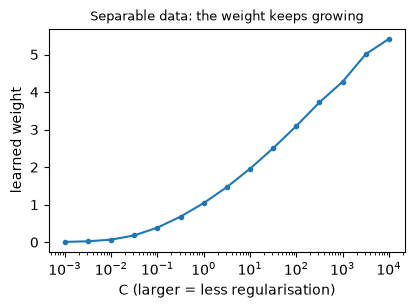

In [10]:
from sklearn.linear_model import LogisticRegression


def separable_weights():
    x = np.array([1, 2, 3, 6, 7, 8], dtype=float).reshape(-1, 1)
    y = np.array([0, 0, 0, 1, 1, 1])
    Cs = np.logspace(-3, 4, 15)
    weights = [LogisticRegression(C=c, max_iter=5000).fit(x, y).coef_[0, 0] for c in Cs]
    fig, ax = plt.subplots(figsize=(4.6, 2.9))
    ax.semilogx(Cs, weights, "o-", markersize=3)
    ax.set_xlabel("C (larger = less regularisation)")
    ax.set_ylabel("learned weight")
    ax.set_title("Separable data: the weight keeps growing", fontsize=9)


separable_weights()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q14](#q14), [Q18](#q18). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [11]:
from scipy.special import expit, logit, softmax

import math

from sklearn.linear_model import LogisticRegression, Perceptron

from sklearn.metrics import log_loss, accuracy_score, zero_one_loss

from sklearn.preprocessing import Binarizer, label_binarize


<a id="q1"></a>
### Q1. Sigmoid Probabilities

🟢 Warm-up · *Score → probability*

Turn raw scores z into probabilities σ(z) = 1/(1 + e⁻ᶻ), rounded to 4 decimals.

**Examples**

- `z = [-2, 0, 1, 3]` → `[0.1192, 0.5, 0.7311, 0.9526]`

In [ ]:
def sigmoid(z):
    """
    Turn raw scores z into probabilities σ(z) = 1/(1 + e⁻ᶻ), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sigmoid, [
    (([-2, 0, 1, 3],), [0.1192, 0.5, 0.7311, 0.9526]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`math.exp` in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`scipy.special.expit` (sklearn uses it inside LogisticRegression).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** `math.exp` in a loop.

```python
def sigmoid(z):
    return [round(1 / (1 + math.exp(-v)), 4) for v in z]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `scipy.special.expit` (sklearn uses it inside LogisticRegression).

```python
def sigmoid(z):
    return expit(np.array(z, dtype=float)).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `math.exp` in a loop. That costs O(n) time and O(n) space."

"I can do better: `scipy.special.expit` (sklearn uses it inside LogisticRegression). That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/sigmoid-probabilities)

<a id="q2"></a>
### Q2. Odds and Log-Odds

🟢 Warm-up · *p → p/(1 − p) → log*

For each probability p return (odds, log-odds), rounded to 4 decimals.

**Examples**

- `ps = [0.5, 0.8, 0.2]` → `[(1.0, 0.0), (4.0, 1.3863), (0.25, -1.3863)]`

In [ ]:
def odds(ps):
    """
    For each probability p return (odds, log-odds), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(odds, [
    (([0.5, 0.8, 0.2],), [(1.0, 0.0), (4.0, 1.3863), (0.25, -1.3863)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

odds = p/(1 − p); log-odds = ln(odds).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`scipy.special.logit` — the inverse of the sigmoid.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** odds = p/(1 − p); log-odds = ln(odds).

```python
def odds(ps):
    out = []
    for p in ps:
        o = p / (1 - p)
        out.append((round(o, 4), round(math.log(o), 4) + 0.0))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `scipy.special.logit` — the inverse of the sigmoid.

```python
def odds(ps):
    p = np.array(ps)
    return [(round(o, 4), round(l, 4) + 0.0) for o, l in zip(p / (1 - p), logit(p))]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: odds = p/(1 − p); log-odds = ln(odds). That costs O(n) time and O(n) space."

"I can do better: `scipy.special.logit` — the inverse of the sigmoid. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/odds-and-log-odds)

<a id="q3"></a>
### Q3. Predict With Given Weights

🟢 Warm-up · *Which side of the line?*

A trained model has weights w and bias b. Return the predicted class (1 if σ(w·x + b) ≥ 0.5) for each row of X.

**Examples**

- `X = [[1, 2], [3, 1], [0, 0], [2, 2]], w = [1.0, -1.5], b = 0.5` → `[0, 1, 1, 0]`

In [ ]:
def predict_given(X, w, b):
    """
    A trained model has weights w and bias b. Return the predicted class (1 if
    σ(w·x + b) ≥ 0.5) for each row of X.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(predict_given, [
    (([[1, 2], [3, 1], [0, 0], [2, 2]], [1.0, -1.5], 0.5), [0, 1, 1, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Score each row; positive score ⇔ probability ≥ 0.5.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Give a `LogisticRegression` those coefficients and call `predict`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Score each row; positive score ⇔ probability ≥ 0.5.

```python
def predict_given(X, w, b):
    out = []
    for row in X:
        z = b + sum(wi * xi for wi, xi in zip(w, row))
        out.append(1 if z >= 0 else 0)
    return out
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Give a `LogisticRegression` those coefficients and call `predict`.

```python
def predict_given(X, w, b):
    model = LogisticRegression()
    model.coef_, model.intercept_, model.classes_ = np.array([w]), np.array([b]), np.array([0, 1])
    return model.predict(np.array(X, dtype=float))
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Score each row; positive score ⇔ probability ≥ 0.5. That costs O(n·d) time and O(n) space."

"I can do better: Give a `LogisticRegression` those coefficients and call `predict`. That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/predict-with-given-weights)

<a id="q4"></a>
### Q4. Binary Log-Loss

🟢 Warm-up · *The training loss*

Return the average log-loss of probabilities p for labels y, rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1], p = [0.9, 0.2, 0.6, 0.95]` → `0.2227`
- `y = [0, 1], p = [0.5, 0.5]` → `0.6931`

In [ ]:
def binary_log_loss(y, p):
    """
    Return the average log-loss of probabilities p for labels y, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(binary_log_loss, [
    (([1, 0, 1, 1], [0.9, 0.2, 0.6, 0.95]), 0.2227),
    (([0, 1], [0.5, 0.5]), 0.6931),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

−ln p for positives, −ln(1 − p) for negatives, averaged.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sklearn.metrics.log_loss`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** −ln p for positives, −ln(1 − p) for negatives, averaged.

```python
def binary_log_loss(y, p):
    total = 0
    for label, prob in zip(y, p):
        total += -math.log(prob) if label == 1 else -math.log(1 - prob)
    return round(total / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `sklearn.metrics.log_loss`.

```python
def binary_log_loss(y, p):
    return round(log_loss(y, p), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: −ln p for positives, −ln(1 − p) for negatives, averaged. That costs O(n) time and O(1) space."

"I can do better: `sklearn.metrics.log_loss`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/binary-log-loss)

<a id="q5"></a>
### Q5. Accuracy

🟢 Warm-up · *Share of correct predictions*

Return the fraction of predictions equal to the true labels, rounded to 4 decimals.

**Examples**

- `y_true = [1, 0, 1, 1, 0], y_pred = [1, 0, 0, 1, 1]` → `0.6`
- `y_true = ['a', 'b'], y_pred = ['a', 'b']` → `1.0`

In [ ]:
def accuracy(y_true, y_pred):
    """
    Return the fraction of predictions equal to the true labels, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(accuracy, [
    (([1, 0, 1, 1, 0], [1, 0, 0, 1, 1]), 0.6),
    ((['a', 'b'], ['a', 'b']), 1.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count matches in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`accuracy_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count matches in a loop.

```python
def accuracy(y_true, y_pred):
    correct = sum(1 for a, b in zip(y_true, y_pred) if a == b)
    return round(correct / len(y_true), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `accuracy_score`.

```python
def accuracy(y_true, y_pred):
    return round(accuracy_score(y_true, y_pred), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count matches in a loop. That costs O(n) time and O(1) space."

"I can do better: `accuracy_score`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/accuracy)

<a id="q6"></a>
### Q6. Move the Threshold

🟢 Warm-up · *Trading precision for recall*

Return 1 for every probability strictly greater than threshold t, else 0.

**Examples**

- `probs = [0.1, 0.4, 0.55, 0.8], t = 0.5` → `[0.0, 0.0, 1.0, 1.0]`
- `probs = [0.1, 0.4, 0.55, 0.8], t = 0.3` → `[0.0, 1.0, 1.0, 1.0]`

In [ ]:
def threshold(probs, t):
    """
    Return 1 for every probability strictly greater than threshold t, else 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(threshold, [
    (([0.1, 0.4, 0.55, 0.8], 0.5), [0.0, 0.0, 1.0, 1.0]),
    (([0.1, 0.4, 0.55, 0.8], 0.3), [0.0, 1.0, 1.0, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare each probability with t.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Binarizer(threshold=t)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compare each probability with t.

```python
def threshold(probs, t):
    return [1.0 if p > t else 0.0 for p in probs]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `Binarizer(threshold=t)`.

```python
def threshold(probs, t):
    return Binarizer(threshold=t).fit_transform(np.array(probs).reshape(-1, 1)).ravel()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare each probability with t. That costs O(n) time and O(n) space."

"I can do better: `Binarizer(threshold=t)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/move-the-threshold)

<a id="q7"></a>
### Q7. Softmax for Many Classes

🟢 Warm-up · *Scores → class probabilities*

Turn each row of scores into probabilities with softmax, rounded to 4 decimals.

**Examples**

- `scores = [[2, 1, 0], [0, 0, 0]]` → `[[0.6652, 0.2447, 0.09], [0.3333, 0.3333, 0.3333]]`

In [ ]:
def softmax_rows(scores):
    """
    Turn each row of scores into probabilities with softmax, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(softmax_rows, [
    (([[2, 1, 0], [0, 0, 0]],), [[0.6652, 0.2447, 0.09], [0.3333, 0.3333, 0.3333]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Exponentiate (after subtracting the row max) and divide by the row sum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`scipy.special.softmax(scores, axis=1)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Exponentiate (after subtracting the row max) and divide by the row sum.

```python
def softmax_rows(scores):
    out = []
    for row in scores:
        top = max(row)
        e = [math.exp(v - top) for v in row]
        s = sum(e)
        out.append([round(v / s, 4) for v in e])
    return out
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `scipy.special.softmax(scores, axis=1)`.

```python
def softmax_rows(scores):
    return softmax(np.array(scores, dtype=float), axis=1).round(4)
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Exponentiate (after subtracting the row max) and divide by the row sum. That costs O(n·k) time and O(n·k) space."

"I can do better: `scipy.special.softmax(scores, axis=1)`. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/softmax-for-many-classes)

<a id="q8"></a>
### Q8. One-vs-Rest Targets

🟢 Warm-up · *One binary problem per class*

Turn class labels into a 0/1 column per class (sorted classes) — the targets of one-vs-rest training.

**Examples**

- `y = ['cat', 'dog', 'bird', 'cat']` → `[[0, 1, 0], [0, 0, 1], [1, 0, 0], [0, 1, 0]]`

In [ ]:
def one_vs_rest(y):
    """
    Turn class labels into a 0/1 column per class (sorted classes) — the targets
    of one-vs-rest training.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(one_vs_rest, [
    ((['cat', 'dog', 'bird', 'cat'],), [[0, 1, 0], [0, 0, 1], [1, 0, 0], [0, 1, 0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each class, mark rows equal to it.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`label_binarize(y, classes=…)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** For each class, mark rows equal to it.

```python
def one_vs_rest(y):
    classes = sorted(set(y))
    return [[1 if label == c else 0 for c in classes] for label in y]
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `label_binarize(y, classes=…)`.

```python
def one_vs_rest(y):
    return label_binarize(y, classes=sorted(set(y)))
```

**Cost:** O(n·k) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each class, mark rows equal to it. That costs O(n·k) time and O(n·k) space."

"I can do better: `label_binarize(y, classes=…)`. That's O(n·k) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/one-vs-rest-targets)

<a id="q9"></a>
### Q9. Count the Mistakes

🟢 Warm-up · *Zero-one loss*

Return how many predictions are wrong.

**Examples**

- `y_true = [1, 0, 1, 1, 0], y_pred = [1, 1, 1, 0, 0]` → `2`

In [ ]:
def mistakes(y_true, y_pred):
    """
    Return how many predictions are wrong.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mistakes, [
    (([1, 0, 1, 1, 0], [1, 1, 1, 0, 0]), 2),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count mismatches.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`zero_one_loss(y, y_pred, normalize=False)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count mismatches.

```python
def mistakes(y_true, y_pred):
    return sum(1 for a, b in zip(y_true, y_pred) if a != b)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `zero_one_loss(y, y_pred, normalize=False)`.

```python
def mistakes(y_true, y_pred):
    return int(zero_one_loss(y_true, y_pred, normalize=False))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count mismatches. That costs O(n) time and O(1) space."

"I can do better: `zero_one_loss(y, y_pred, normalize=False)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/count-the-mistakes)

<a id="q10"></a>
### Q10. Probabilities for New Points

🟡 Interview standard · *predict\_proba*

Train on (x, y) without regularisation and return P(y = 1) for each new x, rounded to 3 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5, 6], y = [0, 0, 1, 0, 1, 1], new_x = [0, 3.5, 7]` → `[0.014, 0.5, 0.986]`

In [ ]:
def proba_new(x, y, new_x):
    """
    Train on (x, y) without regularisation and return P(y = 1) for each new x,
    rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(proba_new, [
    (([1, 2, 3, 4, 5, 6], [0, 0, 1, 0, 1, 1], [0, 3.5, 7]), [0.014, 0.5, 0.986]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Newton fit, then the sigmoid of w·x + b.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`model.predict_proba(X_new)[:, 1]`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Newton fit, then the sigmoid of w·x + b.

```python
def newton_logistic(X, y, C=None, iters=50, weights=None):
    """Fit logistic regression exactly by Newton's method (sklearn's objective: Σ weight·log-loss + ‖w‖²/2C)."""
    A = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    y = np.array(y, dtype=float)
    s = np.ones(len(y)) if weights is None else np.array(weights, dtype=float)
    w = np.zeros(A.shape[1])
    penalty = np.eye(A.shape[1]) / C if C else np.zeros((A.shape[1], A.shape[1]))
    penalty[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-A @ w))
        grad = A.T @ (s * (p - y)) + penalty @ w
        H = A.T @ (A * (s * p * (1 - p))[:, None]) + penalty
        w = w - np.linalg.solve(H, grad)
    return w


def proba_new(x, y, new_x):
    b, w = newton_logistic([[v] for v in x], y)
    return [round(1 / (1 + math.exp(-(w * v + b))), 3) for v in new_x]
```

**Cost:** O(iters·n) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `model.predict_proba(X_new)[:, 1]`.

```python
def proba_new(x, y, new_x):
    model = LogisticRegression(C=1e10, tol=1e-10, max_iter=1000).fit(np.array(x).reshape(-1, 1), y)
    return model.predict_proba(np.array(new_x).reshape(-1, 1))[:, 1].round(3)
```

**Cost:** O(iters·n) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Newton fit, then the sigmoid of w·x + b. That costs O(iters·n) time and O(m) space."

"I can do better: `model.predict_proba(X_new)[:, 1]`. That's O(iters·n) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/probabilities-for-new-points)

<a id="q11"></a>
### Q11. Find the Decision Boundary

🟡 Interview standard · *Where p = 0.5*

Train on (x, y) without regularisation. Return the x where the predicted probability is exactly 0.5, rounded to 3 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5, 6], y = [0, 0, 1, 0, 1, 1]` → `3.5`

In [ ]:
def boundary(x, y):
    """
    Train on (x, y) without regularisation. Return the x where the predicted
    probability is exactly 0.5, rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(boundary, [
    (([1, 2, 3, 4, 5, 6], [0, 0, 1, 0, 1, 1]), 3.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

σ(z) = 0.5 ⇔ z = 0 ⇔ x = −b/w.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same formula with the fitted sklearn coefficients.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** σ(z) = 0.5 ⇔ z = 0 ⇔ x = −b/w.

```python
def newton_logistic(X, y, C=None, iters=50, weights=None):
    """Fit logistic regression exactly by Newton's method (sklearn's objective: Σ weight·log-loss + ‖w‖²/2C)."""
    A = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    y = np.array(y, dtype=float)
    s = np.ones(len(y)) if weights is None else np.array(weights, dtype=float)
    w = np.zeros(A.shape[1])
    penalty = np.eye(A.shape[1]) / C if C else np.zeros((A.shape[1], A.shape[1]))
    penalty[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-A @ w))
        grad = A.T @ (s * (p - y)) + penalty @ w
        H = A.T @ (A * (s * p * (1 - p))[:, None]) + penalty
        w = w - np.linalg.solve(H, grad)
    return w


def boundary(x, y):
    b, w = newton_logistic([[v] for v in x], y)
    return round(-b / w, 3)
```

**Cost:** O(iters·n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Same formula with the fitted sklearn coefficients.

```python
def boundary(x, y):
    model = LogisticRegression(C=1e10, tol=1e-10, max_iter=1000).fit(np.array(x).reshape(-1, 1), y)
    return round(-model.intercept_[0] / model.coef_[0, 0], 3)
```

**Cost:** O(iters·n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: σ(z) = 0.5 ⇔ z = 0 ⇔ x = −b/w. That costs O(iters·n) time and O(1) space."

"I can do better: Same formula with the fitted sklearn coefficients. That's O(iters·n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/find-the-decision-boundary)

<a id="q12"></a>
### Q12. Odds Ratio of a Feature

🟡 Interview standard · *Interpreting a coefficient*

Train on (x, y) without regularisation. Return e^w — how the odds of class 1 multiply when x grows by 1 — rounded to 3 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5, 6], y = [0, 0, 1, 0, 1, 1]` → `3.367`

In [ ]:
def odds_ratio(x, y):
    """
    Train on (x, y) without regularisation. Return e^w — how the odds of class 1
    multiply when x grows by 1 — rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(odds_ratio, [
    (([1, 2, 3, 4, 5, 6], [0, 0, 1, 0, 1, 1]), 3.367),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Newton fit, then exp of the weight.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.exp(model.coef_)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Newton fit, then exp of the weight.

```python
def newton_logistic(X, y, C=None, iters=50, weights=None):
    """Fit logistic regression exactly by Newton's method (sklearn's objective: Σ weight·log-loss + ‖w‖²/2C)."""
    A = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    y = np.array(y, dtype=float)
    s = np.ones(len(y)) if weights is None else np.array(weights, dtype=float)
    w = np.zeros(A.shape[1])
    penalty = np.eye(A.shape[1]) / C if C else np.zeros((A.shape[1], A.shape[1]))
    penalty[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-A @ w))
        grad = A.T @ (s * (p - y)) + penalty @ w
        H = A.T @ (A * (s * p * (1 - p))[:, None]) + penalty
        w = w - np.linalg.solve(H, grad)
    return w


def odds_ratio(x, y):
    b, w = newton_logistic([[v] for v in x], y)
    return round(math.exp(w), 3)
```

**Cost:** O(iters·n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.exp(model.coef_)`.

```python
def odds_ratio(x, y):
    model = LogisticRegression(C=1e10, tol=1e-10, max_iter=1000).fit(np.array(x).reshape(-1, 1), y)
    return round(np.exp(model.coef_[0, 0]), 3)
```

**Cost:** O(iters·n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Newton fit, then exp of the weight. That costs O(iters·n) time and O(1) space."

"I can do better: `np.exp(model.coef_)`. That's O(iters·n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/odds-ratio-of-a-feature)

<a id="q13"></a>
### Q13. Multiclass Prediction From Weights

🟡 Interview standard · *Highest score wins*

W has one row of weights per class (classes 0, 1, 2…), b one bias per class. Return the predicted class of each row of X.

**Examples**

- `W = [[1, 0], [0, 1], [-1, -1]], X = [[2, 1], [0, 3], [-2, -2]], b = [0, 0, 1]` → `[0, 1, 2]`

In [ ]:
def multiclass_predict(W, X, b):
    """
    W has one row of weights per class (classes 0, 1, 2…), b one bias per class.
    Return the predicted class of each row of X.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(multiclass_predict, [
    (([[1, 0], [0, 1], [-1, -1]], [[2, 1], [0, 3], [-2, -2]], [0, 0, 1]), [0, 1, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Score every class for every row, take the largest.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A `LogisticRegression` holding those coefficients; `predict` takes the argmax.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Score every class for every row, take the largest.

```python
def multiclass_predict(W, X, b):
    out = []
    for row in X:
        scores = [bk + sum(w * x for w, x in zip(wk, row)) for wk, bk in zip(W, b)]
        out.append(scores.index(max(scores)))
    return out
```

**Cost:** O(n·k·d) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** A `LogisticRegression` holding those coefficients; `predict` takes the argmax.

```python
def multiclass_predict(W, X, b):
    model = LogisticRegression()
    model.coef_, model.intercept_ = np.array(W, dtype=float), np.array(b, dtype=float)
    model.classes_ = np.arange(len(W))
    return model.predict(np.array(X, dtype=float))
```

**Cost:** O(n·k·d) time, O(n·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Score every class for every row, take the largest. That costs O(n·k·d) time and O(k) space."

"I can do better: A `LogisticRegression` holding those coefficients; `predict` takes the argmax. That's O(n·k·d) time and O(n·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/multiclass-prediction-from-weights)

<a id="q14"></a>
### Q14. Multiclass Log-Loss

🟡 Interview standard · *Categorical cross-entropy*

Each row of P holds class probabilities; y holds the true class index. Return the mean of −ln P[true class], rounded to 4 decimals.

**Examples**

- `y = [0, 2, 1], P = [[0.7, 0.2, 0.1], [0.1, 0.1, 0.8], [0.3, 0.4, 0.3]]` → `0.4987`

In [ ]:
def multi_log_loss(y, P):
    """
    Each row of P holds class probabilities; y holds the true class index.
    Return the mean of −ln P[true class], rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(multi_log_loss, [
    (([0, 2, 1], [[0.7, 0.2, 0.1], [0.1, 0.1, 0.8], [0.3, 0.4, 0.3]]), 0.4987),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Pick out the true class's probability in each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`log_loss(y, P, labels=[0, 1, 2])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Pick out the true class's probability in each row.

```python
def multi_log_loss(y, P):
    return round(sum(-math.log(row[c]) for c, row in zip(y, P)) / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `log_loss(y, P, labels=[0, 1, 2])`.

```python
def multi_log_loss(y, P):
    return round(log_loss(y, P, labels=list(range(len(P[0])))), 4)
```

**Cost:** O(n·k) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Pick out the true class's probability in each row. That costs O(n) time and O(1) space."

"I can do better: `log_loss(y, P, labels=[0, 1, 2])`. That's O(n·k) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/multiclass-log-loss)

<a id="q15"></a>
### Q15. Gradient of the Log-Loss

🟡 Interview standard · *Xᵀ(p − y) / n*

At weights w and bias b, return the gradient of the average log-loss as [∂/∂b, ∂/∂w₁, …], rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2]], y = [0, 0, 1, 0, 1, 1, 1, 0], w = [0.5, -0.5], b = 0.0` → `[0.0822, 0.222, -0.3085]`

In [ ]:
def logloss_grad(X, y, w, b):
    """
    At weights w and bias b, return the gradient of the average log-loss as
    [∂/∂b, ∂/∂w₁, …], rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(logloss_grad, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2]], [0, 0, 1, 0, 1, 1, 1, 0], [0.5, -0.5], 0.0), [0.0822, 0.222, -0.3085]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over examples, accumulating (p − y)·x.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised NumPy: `A.T @ (expit(A @ w) - y) / n` with a column of 1s in A.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over examples, accumulating (p − y)·x.

```python
def logloss_grad(X, y, w, b):
    n = len(X)
    g = [0.0] * (len(w) + 1)
    for row, target in zip(X, y):
        p = 1 / (1 + math.exp(-(b + sum(a * c for a, c in zip(w, row)))))
        g[0] += (p - target) / n
        for j, x in enumerate(row):
            g[j + 1] += (p - target) * x / n
    return [round(v, 4) for v in g]
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Vectorised NumPy: `A.T @ (expit(A @ w) - y) / n` with a column of 1s in A.

```python
def logloss_grad(X, y, w, b):
    A = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    p = expit(A @ np.concatenate([[b], w]))
    return (A.T @ (p - np.array(y)) / len(y)).round(4)
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over examples, accumulating (p − y)·x. That costs O(n·d) time and O(d) space."

"I can do better: Vectorised NumPy: `A.T @ (expit(A @ w) - y) / n` with a column of 1s in A. That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/gradient-of-the-log-loss)

<a id="q16"></a>
### Q16. Train Logistic Regression (One Feature)

🔴 Stretch · *Newton's method*

Fit an unregularised logistic regression P(y = 1) = σ(w·x + b). Return (w, b) rounded to 3 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5, 6], y = [0, 0, 1, 0, 1, 1]` → `(1.214, -4.249)`

In [ ]:
def train_1d(x, y):
    """
    Fit an unregularised logistic regression P(y = 1) = σ(w·x + b). Return (w,
    b) rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(train_1d, [
    (([1, 2, 3, 4, 5, 6], [0, 0, 1, 0, 1, 1]), (1.214, -4.249)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Newton's method from scratch: gradient Aᵀ(p − y), Hessian AᵀSA, update w ← w − H⁻¹g, ~20 iterations.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LogisticRegression(C=1e10)` — a huge C means (almost) no penalty.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Newton's method from scratch: gradient Aᵀ(p − y), Hessian AᵀSA, update w ← w − H⁻¹g, ~20 iterations.

```python
def newton_logistic(X, y, C=None, iters=50, weights=None):
    """Fit logistic regression exactly by Newton's method (sklearn's objective: Σ weight·log-loss + ‖w‖²/2C)."""
    A = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    y = np.array(y, dtype=float)
    s = np.ones(len(y)) if weights is None else np.array(weights, dtype=float)
    w = np.zeros(A.shape[1])
    penalty = np.eye(A.shape[1]) / C if C else np.zeros((A.shape[1], A.shape[1]))
    penalty[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-A @ w))
        grad = A.T @ (s * (p - y)) + penalty @ w
        H = A.T @ (A * (s * p * (1 - p))[:, None]) + penalty
        w = w - np.linalg.solve(H, grad)
    return w


def train_1d(x, y):
    b, w = newton_logistic([[v] for v in x], y)
    return (round(w, 3), round(b, 3))
```

**Cost:** O(iters·n·d²) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LogisticRegression(C=1e10)` — a huge C means (almost) no penalty.

```python
def train_1d(x, y):
    model = LogisticRegression(C=1e10, tol=1e-10, max_iter=1000).fit(np.array(x).reshape(-1, 1), y)
    return (round(model.coef_[0, 0], 3), round(model.intercept_[0], 3))
```

**Cost:** O(iters·n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Newton's method from scratch: gradient Aᵀ(p − y), Hessian AᵀSA, update w ← w − H⁻¹g, ~20 iterations. That costs O(iters·n·d²) time and O(d²) space."

"I can do better: `LogisticRegression(C=1e10)` — a huge C means (almost) no penalty. That's O(iters·n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/train-logistic-regression-one-feature)

<a id="q17"></a>
### Q17. Train Logistic Regression (Two Features)

🔴 Stretch · *Regularised, C = 1*

Fit logistic regression with sklearn's default L2 penalty (C = 1). Return [b, w₁, w₂] rounded to 3 decimals.

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2]], y = [0, 0, 1, 0, 1, 1, 1, 0]` → `[-3.483, -0.013, 1.32]`

In [ ]:
def train_2d(X, y):
    """
    Fit logistic regression with sklearn's default L2 penalty (C = 1). Return
    [b, w₁, w₂] rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(train_2d, [
    (([[1, 2], [2, 1], [3, 3], [4, 2], [5, 5], [6, 4], [2, 3], [5, 2]], [0, 0, 1, 0, 1, 1, 1, 0]), [-3.483, -0.013, 1.32]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Newton's method on Σ log-loss + ‖w‖²/2 (the bias isn't penalised).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LogisticRegression(C=1.0)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Newton's method on Σ log-loss + ‖w‖²/2 (the bias isn't penalised).

```python
def newton_logistic(X, y, C=None, iters=50, weights=None):
    """Fit logistic regression exactly by Newton's method (sklearn's objective: Σ weight·log-loss + ‖w‖²/2C)."""
    A = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    y = np.array(y, dtype=float)
    s = np.ones(len(y)) if weights is None else np.array(weights, dtype=float)
    w = np.zeros(A.shape[1])
    penalty = np.eye(A.shape[1]) / C if C else np.zeros((A.shape[1], A.shape[1]))
    penalty[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-A @ w))
        grad = A.T @ (s * (p - y)) + penalty @ w
        H = A.T @ (A * (s * p * (1 - p))[:, None]) + penalty
        w = w - np.linalg.solve(H, grad)
    return w


def train_2d(X, y):
    return newton_logistic(X, y, C=1.0).round(3)
```

**Cost:** O(iters·n·d²) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LogisticRegression(C=1.0)`.

```python
def train_2d(X, y):
    model = LogisticRegression(C=1.0, tol=1e-10, max_iter=1000).fit(X, y)
    return np.concatenate([model.intercept_, model.coef_[0]]).round(3)
```

**Cost:** O(iters·n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Newton's method on Σ log-loss + ‖w‖²/2 (the bias isn't penalised). That costs O(iters·n·d²) time and O(d²) space."

"I can do better: `LogisticRegression(C=1.0)`. That's O(iters·n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/train-logistic-regression-two-features)

<a id="q18"></a>
### Q18. Stronger Regularisation, Smaller Weight

🔴 Stretch · *The C parameter*

Fit one-feature logistic regression for each C (penalty ‖w‖²/2C). Return the learned w for each, rounded to 3 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5, 6], y = [0, 0, 1, 0, 1, 1], Cs = [0.01, 0.1, 1, 100]` → `[0.034, 0.245, 0.767, 1.204]`

In [ ]:
def weight_by_c(x, y, Cs):
    """
    Fit one-feature logistic regression for each C (penalty ‖w‖²/2C). Return the
    learned w for each, rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(weight_by_c, [
    (([1, 2, 3, 4, 5, 6], [0, 0, 1, 0, 1, 1], [0.01, 0.1, 1, 100]), [0.034, 0.245, 0.767, 1.204]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Newton's method once per C.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LogisticRegression(C=c)` once per C.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Newton's method once per C.

```python
def newton_logistic(X, y, C=None, iters=50, weights=None):
    """Fit logistic regression exactly by Newton's method (sklearn's objective: Σ weight·log-loss + ‖w‖²/2C)."""
    A = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    y = np.array(y, dtype=float)
    s = np.ones(len(y)) if weights is None else np.array(weights, dtype=float)
    w = np.zeros(A.shape[1])
    penalty = np.eye(A.shape[1]) / C if C else np.zeros((A.shape[1], A.shape[1]))
    penalty[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-A @ w))
        grad = A.T @ (s * (p - y)) + penalty @ w
        H = A.T @ (A * (s * p * (1 - p))[:, None]) + penalty
        w = w - np.linalg.solve(H, grad)
    return w


def weight_by_c(x, y, Cs):
    return [round(newton_logistic([[v] for v in x], y, C=c)[1], 3) for c in Cs]
```

**Cost:** O(k·iters·n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LogisticRegression(C=c)` once per C.

```python
def weight_by_c(x, y, Cs):
    X = np.array(x).reshape(-1, 1)
    return [round(LogisticRegression(C=c, tol=1e-10, max_iter=1000).fit(X, y).coef_[0, 0], 3) for c in Cs]
```

**Cost:** O(k·iters·n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Newton's method once per C. That costs O(k·iters·n) time and O(k) space."

"I can do better: `LogisticRegression(C=c)` once per C. That's O(k·iters·n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/stronger-regularisation-smaller-weight)

<a id="q19"></a>
### Q19. Class-Weighted Logistic Regression

🔴 Stretch · *Imbalanced data*

Only 2 of 8 examples are positive. Fit logistic regression (C = 1) with class\_weight='balanced' and return [b, w] rounded to 3 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5, 6, 7, 8], y = [0, 0, 0, 1, 0, 0, 1, 0]` → `[-1.363, 0.281]`

In [ ]:
def weighted_logistic(x, y):
    """
    Only 2 of 8 examples are positive. Fit logistic regression (C = 1) with
    class_weight='balanced' and return [b, w] rounded to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(weighted_logistic, [
    (([1, 2, 3, 4, 5, 6, 7, 8], [0, 0, 0, 1, 0, 0, 1, 0]), [-1.363, 0.281]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Weight each example by n / (2 × count of its class), then Newton's method on the weighted loss.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`LogisticRegression(class_weight='balanced')`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Weight each example by n / (2 × count of its class), then Newton's method on the weighted loss.

```python
def newton_logistic(X, y, C=None, iters=50, weights=None):
    """Fit logistic regression exactly by Newton's method (sklearn's objective: Σ weight·log-loss + ‖w‖²/2C)."""
    A = np.column_stack([np.ones(len(X)), np.array(X, dtype=float)])
    y = np.array(y, dtype=float)
    s = np.ones(len(y)) if weights is None else np.array(weights, dtype=float)
    w = np.zeros(A.shape[1])
    penalty = np.eye(A.shape[1]) / C if C else np.zeros((A.shape[1], A.shape[1]))
    penalty[0, 0] = 0
    for _ in range(iters):
        p = 1 / (1 + np.exp(-A @ w))
        grad = A.T @ (s * (p - y)) + penalty @ w
        H = A.T @ (A * (s * p * (1 - p))[:, None]) + penalty
        w = w - np.linalg.solve(H, grad)
    return w


def weighted_logistic(x, y):
    n_pos = sum(y)
    n_neg = len(y) - n_pos
    weights = [len(y) / (2 * n_pos) if label == 1 else len(y) / (2 * n_neg) for label in y]
    return newton_logistic([[v] for v in x], y, C=1.0, weights=weights).round(3)
```

**Cost:** O(iters·n) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `LogisticRegression(class_weight='balanced')`.

```python
def weighted_logistic(x, y):
    model = LogisticRegression(class_weight="balanced", tol=1e-10, max_iter=1000).fit(np.array(x).reshape(-1, 1), y)
    return np.concatenate([model.intercept_, model.coef_[0]]).round(3)
```

**Cost:** O(iters·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Weight each example by n / (2 × count of its class), then Newton's method on the weighted loss. That costs O(iters·n) time and O(d²) space."

"I can do better: `LogisticRegression(class_weight='balanced')`. That's O(iters·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/class-weighted-logistic-regression)

<a id="q20"></a>
### Q20. Train a Perceptron

🔴 Stretch · *The original neural unit*

Train a perceptron (labels 0/1, learning rate 1, no shuffling, 10 passes): on each mistake add (or subtract) the example to the weights and bias. Return [b, w₁, w₂].

**Examples**

- `X = [[2, 1], [3, 4], [-1, -2], [-2, 1], [1, 3], [-3, -1]], y = [1, 1, 0, 0, 1, 0]` → `[1.0, 2.0, 1.0]`

In [ ]:
def perceptron(X, y):
    """
    Train a perceptron (labels 0/1, learning rate 1, no shuffling, 10 passes):
    on each mistake add (or subtract) the example to the weights and bias.
    Return [b, w₁, w₂].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(perceptron, [
    (([[2, 1], [3, 4], [-1, -2], [-2, 1], [1, 3], [-3, -1]], [1, 1, 0, 0, 1, 0]), [1.0, 2.0, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over the data in order; if sign(w·x + b) is wrong, w += y·x and b += y with y as ±1.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Perceptron(shuffle=False, eta0=1, max_iter=10, tol=None)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over the data in order; if sign(w·x + b) is wrong, w += y·x and b += y with y as ±1.

```python
def perceptron(X, y):
    w = [0.0] * len(X[0])
    b = 0.0
    for _ in range(10):
        for row, label in zip(X, y):
            target = 1 if label == 1 else -1
            score = b + sum(wi * xi for wi, xi in zip(w, row))
            if target * score <= 0:
                w = [wi + target * xi for wi, xi in zip(w, row)]
                b += target
    return [b] + w
```

**Cost:** O(passes·n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `Perceptron(shuffle=False, eta0=1, max_iter=10, tol=None)`.

```python
def perceptron(X, y):
    model = Perceptron(shuffle=False, eta0=1.0, max_iter=10, tol=None).fit(X, y)
    return np.concatenate([model.intercept_, model.coef_[0]])
```

**Cost:** O(passes·n·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over the data in order; if sign(w·x + b) is wrong, w += y·x and b += y with y as ±1. That costs O(passes·n·d) time and O(d) space."

"I can do better: `Perceptron(shuffle=False, eta0=1, max_iter=10, tol=None)`. That's O(passes·n·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/logistic-regression/train-a-perceptron)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why is it called regression if it classifies?</b></summary>

It regresses the log-odds of the class on the features (a linear model for the log-odds); the classification comes from thresholding the resulting probability.

</details>

<details>
<summary><b>2. Why not use linear regression for classification?</b></summary>

Its outputs aren't bounded to [0, 1], squared error is a poor loss for 0/1 targets, and outliers shift the boundary badly. The sigmoid plus log-loss fixes all three.

</details>

<details>
<summary><b>3. How do you interpret a logistic regression coefficient?</b></summary>

A one-unit increase in the feature adds w to the log-odds, i.e. multiplies the odds by e^w, holding other features fixed.

</details>

<details>
<summary><b>4. What does C do in sklearn's LogisticRegression?</b></summary>

C is the inverse regularisation strength. Small C = strong penalty, smaller weights, simpler model; large C = weak penalty, risk of overfitting.

</details>

<details>
<summary><b>5. How do you handle class imbalance in logistic regression?</b></summary>

class\_weight='balanced' (or custom weights), resampling, choosing a threshold other than 0.5, and evaluating with precision/recall or PR-AUC instead of accuracy.

</details>

<details>
<summary><b>6. What is the decision boundary of logistic regression?</b></summary>

The set where wᵀx + b = 0 (p = 0.5): a hyperplane, so the model is a linear classifier unless you add non-linear features.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: From a line to a probability
- [ ] I can explain: The sigmoid and odds, by hand
- [ ] I can explain: Training: log-loss
- [ ] I can explain: Decision boundaries in two dimensions
- [ ] I can explain: Where log-loss comes from
- [ ] I can explain: One training step, by hand
- [ ] I can explain: More than two classes, and the perceptron
- [ ] I can explain: Choosing the decision threshold
- [ ] I can explain: Softmax by hand, and when weights explode

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Train Logistic Regression (One Feature)
- [ ] [Q17](#q17) Train Logistic Regression (Two Features)
- [ ] [Q18](#q18) Stronger Regularisation, Smaller Weight
- [ ] [Q19](#q19) Class-Weighted Logistic Regression
- [ ] [Q20](#q20) Train a Perceptron

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.